In [1]:
# Question 1.1
# Import the required libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)


In [2]:
# Question 1.1
# Load the JSON dataset
df = pd.read_json("../datasets/research_abstracts.json")

# Display the first five records
display(df.head())

# Check the dataset information
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check for duplicate abstracts
print("\nDuplicate abstracts:", df["Abstract"].duplicated().sum())

# Display the research categories
print("\nResearch categories:")
print(df["Label"].value_counts())


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


Dataset shape: (1138, 3)

Column names: ['DOI', 'Abstract', 'Label']

Missing values:
DOI         4
Abstract    0
Label       0
dtype: int64

Duplicate abstracts: 13

Research categories:
Label
classical    900
ai           238
Name: count, dtype: int64


In [3]:
# Question 1.1
# Remove records with missing abstracts or labels
df = df.dropna(subset=["Abstract", "Label"]).copy()

# Convert abstracts to lowercase
df["clean_text"] = df["Abstract"].str.lower()

# Remove website links
df["clean_text"] = df["clean_text"].str.replace(
    r"https?://\S+|www\.\S+", " ", regex=True
)

# Remove numbers and special characters
df["clean_text"] = df["clean_text"].str.replace(
    r"[^a-z\s]", " ", regex=True
)

# Remove unnecessary spaces
df["clean_text"] = df["clean_text"].str.replace(
    r"\s+", " ", regex=True
).str.strip()

# Remove empty and duplicate cleaned abstracts
df = df[df["clean_text"] != ""]
df = df.drop_duplicates(subset=["clean_text"]).copy()

# Display the cleaned data
print("Cleaned dataset shape:", df.shape)
display(df[["Abstract", "clean_text", "Label"]].head())


Cleaned dataset shape: (1121, 4)


,Abstract,clean_text,Label
0,Forward-looking forecasting of the inflation r...,forward looking forecasting of the inflation r...,ai
1,Our study examined the disaggregation of infla...,our study examined the disaggregation of infla...,ai
2,This paper develops a dynamic factor model tha...,this paper develops a dynamic factor model tha...,classical
3,"In this paper, I use a simple SIR Macro model ...",in this paper i use a simple sir macro model t...,classical
4,BackgroundGame theory is useful for identifyin...,backgroundgame theory is useful for identifyin...,classical


In [4]:
# Question 1.2
# Select input and target variables
X = df["clean_text"]
y = df["Label"]

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into numerical features using TF-IDF
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2
)

# Fit only on training data
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Display feature engineering results
print("Training records:", X_train_tfidf.shape[0])
print("Testing records:", X_test_tfidf.shape[0])
print("Number of TF-IDF features:", X_train_tfidf.shape[1])

# Display some important text terms
terms = vectorizer.get_feature_names_out()
scores = X_train_tfidf.mean(axis=0).A1
top_terms = scores.argsort()[-10:][::-1]

print("\nCommon TF-IDF terms:")
print(terms[top_terms])


Training records: 896
Testing records: 225
Number of TF-IDF features: 3000

Common TF-IDF terms:
['inflation' 'model' 'rate' 'price' 'models' 'data' 'forecasts' 'policy'
 'economic' 'predictions']


In [5]:
# Question 1.3
# Create the baseline model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
model.fit(X_train_tfidf, y_train)

# Predict training and testing categories
train_pred = model.predict(X_train_tfidf)
test_pred = model.predict(X_test_tfidf)

print("Model training completed successfully!")


Model training completed successfully!


In [6]:
# Question 1.3
# Calculate training and testing accuracy
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

# Calculate F1-scores
train_f1 = f1_score(y_train, train_pred, average="macro")
test_f1 = f1_score(y_test, test_pred, average="macro")

# Display the performance results
print("Training Accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

print("\nTraining Macro F1-score:", round(train_f1, 3))
print("Testing Macro F1-score:", round(test_f1, 3))

# Display classification performance
print("\nClassification Report:")
print(classification_report(y_test, test_pred, digits=3))


Training Accuracy: 97.32 %
Testing Accuracy: 88.89 %

Training Macro F1-score: 0.961
Testing Macro F1-score: 0.838

Classification Report:
              precision    recall  f1-score   support

          ai      0.712     0.787     0.747        47
   classical      0.942     0.916     0.929       178

    accuracy                          0.889       225
   macro avg      0.827     0.851     0.838       225
weighted avg      0.894     0.889     0.891       225



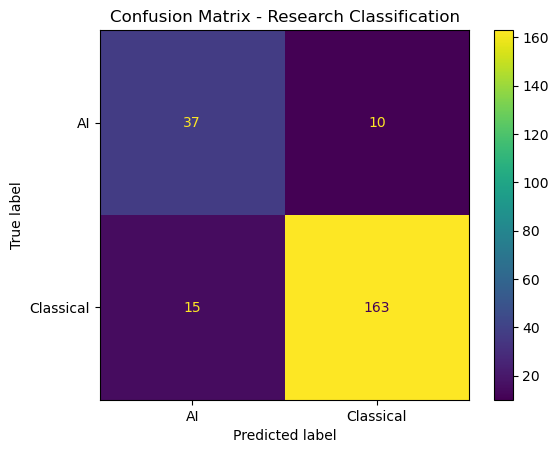

In [7]:
# Question 1.3
# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    labels=["ai", "classical"],
    display_labels=["AI", "Classical"]
)

plt.title("Confusion Matrix - Research Classification")
plt.show()


In [8]:
# Question 2.1
# Import libraries for the four machine learning models
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier


In [9]:
# Question 2.1
# Define the four models
models = {
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "SGD Classifier": SGDClassifier(
        loss="hinge",
        class_weight="balanced",
        random_state=42
    )
}

# Store model results
results = []
trained_models = {}

# Train and evaluate each model
for name, classifier in models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english",
            max_features=3000,
            ngram_range=(1, 2),
            min_df=2
        )),
        ("model", classifier)
    ])

    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Training Accuracy": round(accuracy_score(y_train, train_pred) * 100, 2),
        "Testing Accuracy": round(accuracy_score(y_test, test_pred) * 100, 2),
        "Test Macro F1": round(f1_score(y_test, test_pred, average="macro"), 3)
    })

    trained_models[name] = pipeline

# Display comparison results
results_df = pd.DataFrame(results)
display(results_df.sort_values("Test Macro F1", ascending=False))


,Model,Training Accuracy,Testing Accuracy,Test Macro F1
2,Random Forest,100.00,90.67,0.832
1,Linear SVM,99.89,88.44,0.828
3,SGD Classifier,99.89,88.00,0.817
0,Naive Bayes,91.52,85.78,0.723


In [10]:
# Question 2.2
# Improve Linear SVM using character-level TF-IDF
improved_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        max_features=30000,
        min_df=2,
        sublinear_tf=True
    )),
    ("model", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

# Train the improved model
improved_model.fit(X_train, y_train)

# Make predictions
improved_pred = improved_model.predict(X_test)

# Get original SVM predictions
original_pred = trained_models["Linear SVM"].predict(X_test)

# Compare original and improved SVM
comparison = pd.DataFrame({
    "Model": ["Original SVM", "Improved SVM"],
    "Accuracy": [
        round(accuracy_score(y_test, original_pred) * 100, 2),
        round(accuracy_score(y_test, improved_pred) * 100, 2)
    ],
    "Macro F1": [
        round(f1_score(y_test, original_pred, average="macro"), 3),
        round(f1_score(y_test, improved_pred, average="macro"), 3)
    ]
})

display(comparison)


,Model,Accuracy,Macro F1
0,Original SVM,88.44,0.828
1,Improved SVM,92.44,0.879


Improved Model Classification Report:
              precision    recall  f1-score   support

          ai      0.875     0.745     0.805        47
   classical      0.935     0.972     0.953       178

    accuracy                          0.924       225
   macro avg      0.905     0.858     0.879       225
weighted avg      0.923     0.924     0.922       225



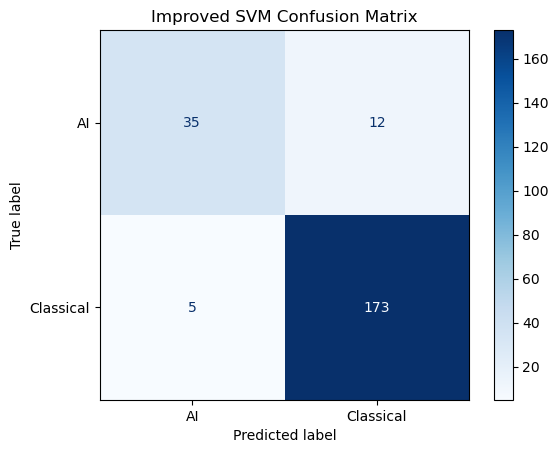

In [11]:
# Question 2.2
# Display the classification report
print("Improved Model Classification Report:")
print(classification_report(y_test, improved_pred, digits=3))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    improved_pred,
    labels=["ai", "classical"],
    display_labels=["AI", "Classical"],
    cmap="Blues"
)

plt.title("Improved SVM Confusion Matrix")
plt.show()


In [12]:
# Question 2.3
# Save the model

# Import libraries for saving the model
import joblib
from sklearn.base import clone

# Retrain the selected model using all cleaned records
final_model = clone(improved_model)

final_model.fit(
    df["clean_text"],
    df["Label"]
)

# Save the model
joblib.dump(final_model, "../deployment/research_classifier.joblib")

print("Model saved successfully!")


Model saved successfully!


In [13]:
# Question 2.3

# Install Streamlit for the web application
%pip install streamlit joblib


Note: you may need to restart the kernel to use updated packages.


In [14]:
%%writefile ../deployment/app.py

import streamlit as st
import joblib
import re
from pathlib import Path

# Configure the web page
st.set_page_config(
    page_title="Researchly Research Abstract Classifier",
    layout="centered"
)

# Load the saved model
@st.cache_resource
def load_model():
    model_path = Path(__file__).parent / "research_classifier.joblib"
    return joblib.load(model_path)

# Apply the same text cleaning used during training
def clean_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Display the title and description
st.title("Researchly Research Abstract Classifier")

st.write(
    "This app classifies research abstracts as either "
    "AI-related or classical research."
)

# Text input field
abstract = st.text_area(
    "Enter research abstract:",
    height=180,
    placeholder="Paste your research abstract here..."
)

# Classification button
if st.button("Classify Abstract"):

    cleaned_abstract = clean_text(abstract)

    if cleaned_abstract == "":
        st.warning("Please enter a research abstract.")

    else:
        # Predict the research category
        model = load_model()
        prediction = model.predict([cleaned_abstract])[0]

        st.subheader("Prediction")

        if prediction == "ai":
            st.success(
                "The abstract is classified as: artificial intelligence"
            )
        else:
            st.success(
                "The abstract is classified as: classical research"
            )


Overwriting ../deployment/app.py


In [15]:
# Question 2.3
# Create requirements file
import sklearn

with open("../deployment/requirements.txt", "w") as file:
    file.write("streamlit\n")
    file.write(f"scikit-learn=={sklearn.__version__}\n")
    file.write("joblib\n")

print("Requirements file created successfully!")


Requirements file created successfully!


In [16]:
import os
print(os.getcwd())

C:\Users\wikus\ITNPA-Project 1-Online Campus-EDUV4818544\Notebooks
